In [1]:
import mne
import numpy as np
import pandas as pd
mne.viz.set_browser_backend("matplotlib")

sample_dir = mne.datasets.sample.data_path() / "MEG" / "sample"
raw = mne.io.read_raw_fif(sample_dir / "sample_audvis_raw.fif")

events = mne.find_events(raw, stim_channel="STI 014")
print(events[:5])
print("first_samp:", raw.first_samp)

Using matplotlib as 2D backend.
Opening raw data file /Users/marcocurran/Downloads/VS Code Profiles/thesis/Masters-Thesis-5th-Year/mne-learning/data/MNE-sample-data/MEG/sample/sample_audvis_raw.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Finding events on: STI 014


/Users/marcocurran/Downloads/VS Code Profiles/thesis/Masters-Thesis-5th-Year/mne-learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


320 events found on stim channel STI 014
Event IDs: [ 1  2  3  4  5 32]
[[27977     0     2]
 [28345     0     3]
 [28771     0     1]
 [29219     0     4]
 [29652     0     2]]
first_samp: 25800


{np.int64(1): np.int64(72), np.int64(2): np.int64(73), np.int64(3): np.int64(73), np.int64(4): np.int64(71), np.int64(5): np.int64(15), np.int64(32): np.int64(16)}


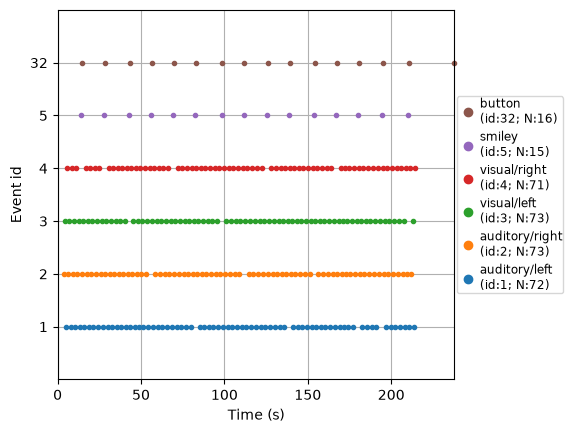

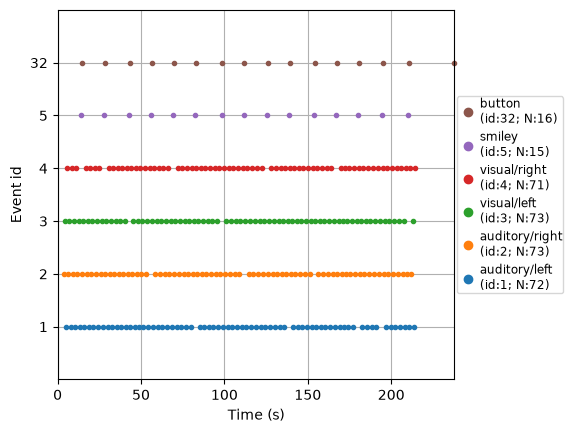

In [2]:
codes, counts = np.unique(events[:, 2], return_counts=True)
print(dict(zip(codes, counts)))

event_id = {"auditory/left": 1, "auditory/right": 2, "visual/left": 3, "visual/right": 4, "smiley": 5, "button": 32}
mne.viz.plot_events(events, sfreq=raw.info["sfreq"], first_samp=raw.first_samp, event_id=event_id)

<Annotations | 5 segments: auditory/left (1), auditory/right (2), ...>
Onsets (s): [46.580589 47.193294 47.902567]


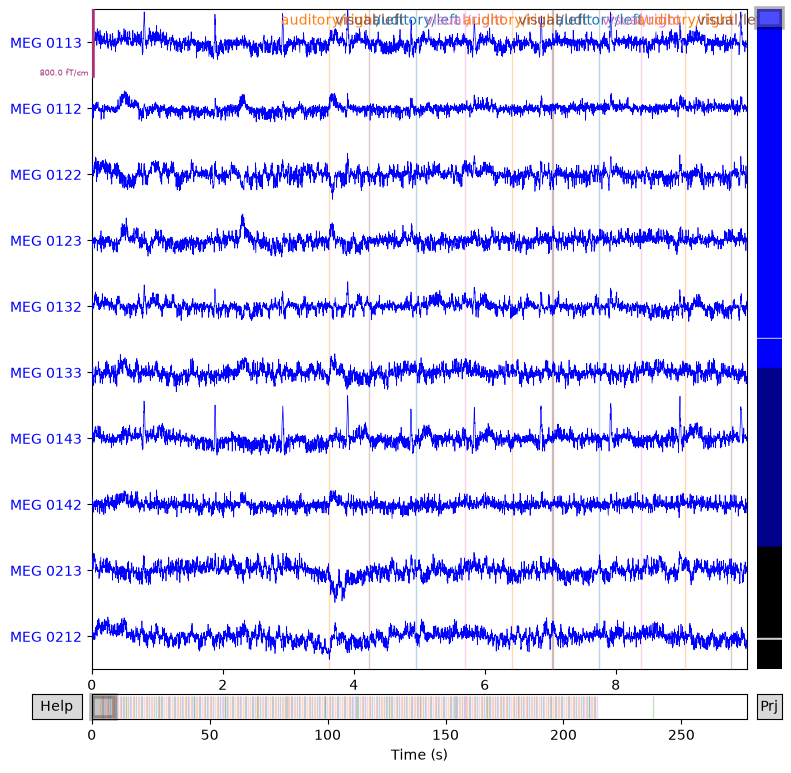

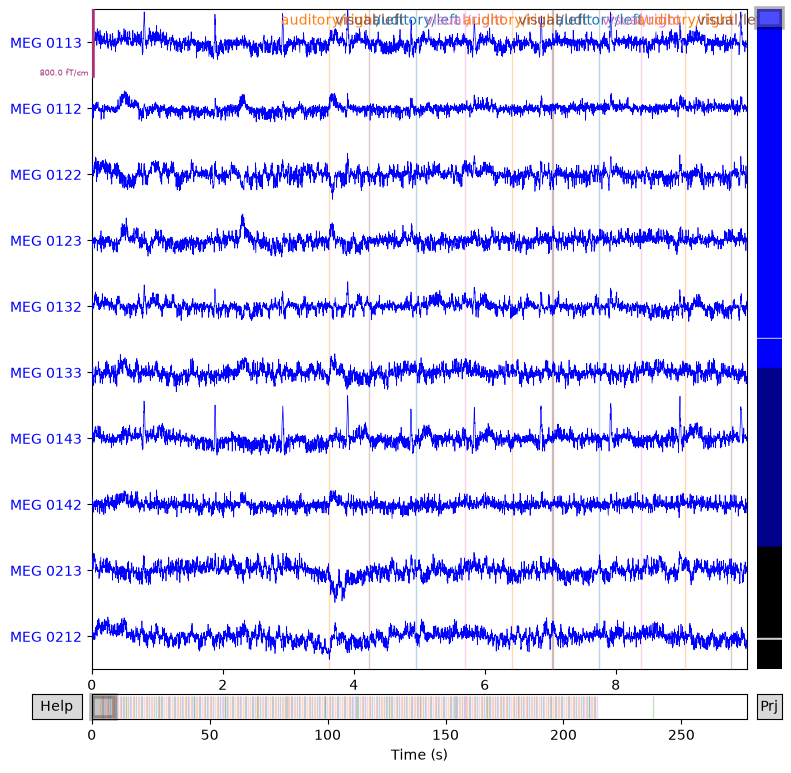

In [ ]:
annot = mne.annotations_from_events(events, sfreq=raw.info["sfreq"], event_desc={v: k for k, v in event_id.items()}, orig_time=raw.info["meas_date"])
raw.set_annotations(annot)

print(raw.annotations[:5])
print("Onsets (s):", raw.annotations.onset[:3])
raw.plot(duration=10, n_channels=10)

In [5]:
events_back, ids_back = mne.events_from_annotations(raw, event_id=event_id)
print(events_back[:5])
print("Identical samples:", np.array_equal(events_back[:, 0], events[:, 0]))

Used Annotations descriptions: ['auditory/left', 'auditory/right', 'button', 'smiley', 'visual/left', 'visual/right']
[[27977     0     2]
 [28345     0     3]
 [28771     0     1]
 [29219     0     4]
 [29652     0     2]]
Identical samples: True


In [6]:
impulse = np.zeros(raw.n_times)
samples = events[events[:, 2] == 1, 0] - raw.first_samp   # make positions file-relative
impulse[samples] = 1

print("Onsets in track:", int(impulse.sum()))
print("Events with code 1:", (events[:, 2] == 1).sum())

Onsets in track: 72
Events with code 1: 72


In [7]:
labels = {v: k for k, v in event_id.items()}
events_tsv = pd.DataFrame({
    "onset": (events[:, 0] - raw.first_samp) / raw.info["sfreq"],
    "duration": 0.0,
    "trial_type": [labels[c] for c in events[:, 2]],
    "value": events[:, 2],
    "sample": events[:, 0] - raw.first_samp,
})
print(events_tsv.head())

      onset  duration      trial_type  value  sample
0  3.624618       0.0  auditory/right      2    2177
1  4.237323       0.0     visual/left      3    2545
2  4.946596       0.0   auditory/left      1    2971
3  5.692499       0.0    visual/right      4    3419
4  6.413426       0.0  auditory/right      2    3852


In [8]:
target_fs = 64.0
secs = (events[:, 0] - raw.first_samp) / raw.info["sfreq"]
new_samples = np.rint(secs * target_fs).astype(int)

error_s = np.abs(new_samples / target_fs - secs)
print("Max timing error: %.2f ms" % (error_s.max() * 1000))
print("Max error in samples:", (error_s * target_fs).max().round(3))
print("Collisions:", len(new_samples) - len(np.unique(new_samples)))

Max timing error: 7.81 ms
Max error in samples: 0.5
Collisions: 0
